# Buổi E1: Bagging, nhiều cái đầu hơn một cái đầu

**Hiện trường.** Chị Hạnh có một cây quyết định (C5) rất giỏi **nhớ** dữ liệu cũ nhưng điểm trên dữ liệu mới thì thất thường: đổi một vài ca trong tập học là cây đổi hẳn dáng. Cô hỏi: *"nếu nhờ **nhiều** cây rồi lấy ý kiến số đông thì sao?"*

Đó là ý tưởng **ensemble** (hòa tấu): nhiều mô hình yếu hoặc thất thường, ghép lại cho kết quả **ổn định hơn**. Buổi đầu của phần E dạy kiểu đơn giản nhất: **bagging** (*bootstrap aggregating*).

**Ẩn dụ:** hỏi ý kiến một nhóm 25 người, mỗi người **chỉ được xem một xấp hồ sơ bốc ngẫu nhiên** từ chồng hồ sơ chung, rồi cả nhóm bỏ phiếu.

**Mindset của người làm dữ liệu:** trước khi tin một mô hình, hỏi *"nếu học lại trên mẫu hơi khác, nó thay đổi nhiều không?"* Nhiều mô hình ghép lại thường là thuốc chữa **phương sai cao** (D2).

**Lưu ý:** dữ liệu sinh ngẫu nhiên hoặc dữ liệu mẫu để học.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: một cây so với 100 cây bỏ phiếu |
| Chặng 1 | Bootstrap: bốc có hoàn lại, mỗi cây thấy một xấp khác |
| Chặng 2 | Tự làm bagging bằng tay: bao nhiêu cây là đủ? |
| Chặng 3 | Hàng sẵn của sklearn và điểm OOB, thi thử miễn phí |
| Chặng 4 | Bagging chữa cho ai? Cây hay mô hình ổn định? |
| Chặng 5 | Giới hạn: khi các cây quá giống nhau |

## Chặng 0: Thấy ngay, một cây và 100 cây bỏ phiếu

**Câu hỏi:** ghép nhiều cây có thật sự tốt hơn một cây?

Dữ liệu: **hai vầng trăng** lồng nhau (`make_moons`), có nhiễu, 400 điểm; nhiễu đủ lớn để cây quyết định không giới hạn **học vẹt**. Ta so một cây và bagging 100 cây.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
X, y = make_moons(n_samples=400, noise=0.35, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
tree = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
bag = BaggingClassifier(DecisionTreeClassifier(), n_estimators=100, random_state=0).fit(X_train, y_train)
print("single tree  | train", round(tree.score(X_train, y_train), 3), "| test", round(tree.score(X_test, y_test), 3))
print("bagged trees | train", round(bag.score(X_train, y_train), 3), "| test", round(bag.score(X_test, y_test), 3))

single tree  | train 1.0 | test 0.792
bagged trees | train 1.0 | test 0.85


**Giải thích từng dòng**

- `make_moons(n_samples=400, noise=0.35, random_state=0)`: sinh 400 điểm hai vầng trăng lồng nhau, nhãn 0 hoặc 1. `noise` là độ nhòe: càng lớn thì hai nhóm càng lấn nhau.
- `DecisionTreeClassifier(random_state=0)`: một cây không giới hạn độ sâu (C5): sẽ nhớ từng điểm học.
- `BaggingClassifier(DecisionTreeClassifier(), n_estimators=100)`: bộ "bỏ phiếu": huấn luyện 100 cây, mỗi cây trên một mẫu bốc ngẫu nhiên (chặng 1), rồi lấy ý kiến số đông. `n_estimators` là số cây.

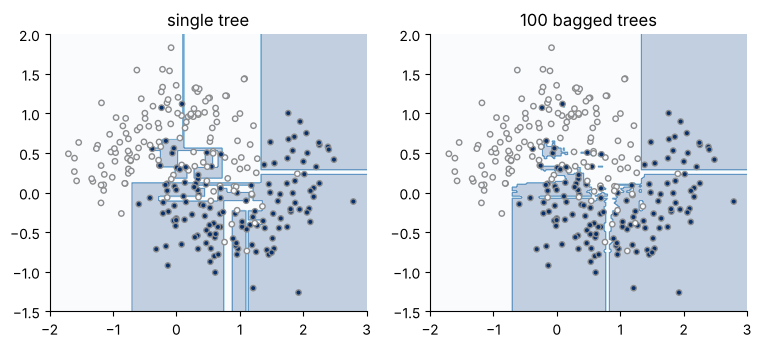

In [3]:
def boundary(ax, model, title):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="Blues")
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="Blues", edgecolor=GRAY, s=15)
    ax.set_title(title)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
boundary(axes[0], tree, "single tree"); boundary(axes[1], bag, "100 bagged trees")
plt.show()

**Giải thích từng dòng**

- `def boundary(ax, model, title):`: hàm vẽ vùng quyết định: tô màu nền theo nhãn mô hình đoán trên một lưới điểm. Đây là hình minh họa, chỉ cần chạy (Decorative diagram: just run it).

**Cách đọc.**
- **Con số:** một cây: học **100,0%**, thi **79,2%**. Bagging 100 cây: học **100,0%**, thi **85,0%**.
- **Bức tranh:** hình trái: ranh giới của một cây **răng cưa**, có những "hòn đảo" nhỏ do nhớ từng điểm nhiễu. Hình phải: bỏ phiếu làm ranh giới **gọn hơn**, ít hòn đảo nhỏ hơn rõ rệt, dù vẫn còn vài chỗ răng cưa. Tập thi chỉ có 120 điểm nên chênh lệch vài điểm phần trăm chưa chắc chắn; hình dạng ranh giới mới là bằng chứng rõ.
- **Câu hỏi tiếp:** "mỗi cây thấy một xấp hồ sơ khác nhau" nghĩa là gì?

**Mang về chặng 0:** nhiều cây bỏ phiếu làm ranh giới mượt hơn, bớt học vẹt từng điểm nhiễu.

## Chặng 1: Bootstrap, bốc có hoàn lại

**Câu hỏi:** làm sao tạo 100 "xấp hồ sơ" khác nhau từ **một** tập học?

Đời thường: chồng 280 hồ sơ. Mỗi lần bốc **một tờ, ghi lại, bỏ lại vào chồng**, bốc đủ 280 lần. Có tờ được bốc 2, 3 lần, có tờ **không được bốc lần nào**. Gọi là **bootstrap** (bốc có hoàn lại).

In [4]:
rng = np.random.RandomState(0)
n = len(X_train)
pick = rng.randint(0, n, size=n)
counts = np.bincount(pick, minlength=n)
print("training rows:", n, "| rows never picked:", int((counts == 0).sum()), "| share unique:", round((counts > 0).mean(), 3))
print("expected share unique for large n: 1 - 1/e =", round(1 - np.exp(-1), 3))

training rows: 280 | rows never picked: 104 | share unique: 0.629
expected share unique for large n: 1 - 1/e = 0.632


**Giải thích từng dòng**

- `rng.randint(0, n, size=n)`: bốc `n` lần, mỗi lần một số từ 0 đến n-1 (vị trí dòng), **có thể trùng**.
- `np.bincount(pick, minlength=n)`: đếm mỗi dòng được bốc bao nhiêu lần.
- `(counts == 0).sum()`: số dòng **chưa từng** được bốc.
- `1 - np.exp(-1)`: xác suất một dòng có mặt ít nhất một lần khi n lớn, xấp xỉ 63,2%.

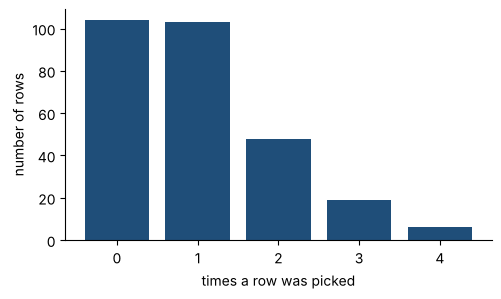

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 3))
ax.bar(*np.unique(counts, return_counts=True), color=BLUE)
ax.set_xlabel("times a row was picked"); ax.set_ylabel("number of rows")
plt.show()

**Giải thích từng dòng**

- `np.unique(counts, return_counts=True)`: liệt kê các giá trị khác nhau (0, 1, 2, ...) và số dòng mang giá trị đó.
- `ax.bar(*...)`: dấu `*` mở hai kết quả thành hai tham số của `bar`.

**Cách đọc.**
- **Con số:** trong 280 dòng, **104** dòng không được bốc (**37,1%**), tức khoảng **62,9%** dòng có mặt, gần 63,2% lý thuyết.
- **Bức tranh:** mỗi cây trong nhóm học trên một xấp **hơi khác** (có dòng đôi, có dòng thiếu). Nhờ vậy 100 cây **không giống hệt nhau** dù cùng thuật toán.
- **Điều bất ngờ có ích:** khoảng một phần ba dòng **bị bỏ ra ngoài** mỗi cây; ta sẽ dùng chúng làm đề thi miễn phí ở chặng 3.

**Mang về chặng 1:** bootstrap tạo nhiều mẫu hơi khác nhau từ một tập; mỗi mẫu chứa khoảng 63% dòng khác nhau.

## Chặng 2: Tự làm bagging bằng tay

**Câu hỏi:** bỏ phiếu số đông hoạt động ra sao, và bao nhiêu cây là đủ?

Ta tự viết: với mỗi cây, bootstrap một xấp, huấn luyện, rồi cho **mỗi cây bỏ một phiếu** cho từng điểm thi. Sau đó đo độ đúng khi dùng 1, 3, 5, ..., 101 cây đầu.

In [6]:
trees, votes = [], []
for i in range(101):
    idx = rng.randint(0, n, size=n)
    t = DecisionTreeClassifier(random_state=i).fit(X_train[idx], y_train[idx])
    trees.append(t)
    votes.append(t.predict(X_test))
votes = np.array(votes)
single_scores = [(v == y_test).mean() for v in votes]
print("votes shape (trees x test points):", votes.shape)
print("average single-tree test score:", round(np.mean(single_scores), 3), "| best:", round(max(single_scores), 3), "| worst:", round(min(single_scores), 3))

votes shape (trees x test points): (101, 120)
average single-tree test score: 0.814 | best: 0.875 | worst: 0.733


**Giải thích từng dòng**

- `X_train[idx], y_train[idx]`: lấy đúng các dòng đã bốc (kể cả dòng trùng) làm tập học riêng của cây này.
- `DecisionTreeClassifier(random_state=i)`: mỗi cây một hạt giống khác (`i`) để cách phá hòa khác nhau.
- `votes = np.array(votes)`: mảng 101 hàng (cây) × số điểm thi: ô (i, j) là nhãn cây i đoán cho điểm j.
- `(v == y_test).mean()`: độ đúng của một cây: tỉ lệ đoán trùng nhãn thật.

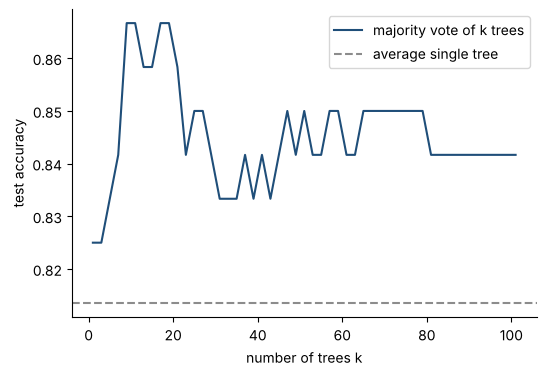

In [7]:
counts_n = list(range(1, 102, 2))
ens_scores = []
for k in counts_n:
    majority = (votes[:k].mean(axis=0) > 0.5).astype(int)
    ens_scores.append((majority == y_test).mean())
fig, ax = plt.subplots()
ax.plot(counts_n, ens_scores, color=BLUE, label="majority vote of k trees")
ax.axhline(np.mean(single_scores), color=GRAY, linestyle="--", label="average single tree")
ax.set_xlabel("number of trees k"); ax.set_ylabel("test accuracy"); ax.legend()
plt.show()

**Giải thích từng dòng**

- `votes[:k].mean(axis=0)`: lấy k cây đầu, tính trung bình các phiếu (0 hoặc 1) theo từng điểm thi: tỉ lệ cây bỏ phiếu cho nhãn 1.
- `> 0.5`: quá nửa số cây chọn 1 thì ensemble chọn 1: **số đông thắng**. Dùng số cây lẻ để tránh hòa.
- `.astype(int)`: đổi đúng/sai thành 1/0.

**Cách đọc.**
- **Con số:** cây đơn trung bình **81,4%** (tốt nhất 87,5%, kém nhất 73,3%). Bỏ phiếu 101 cây: **84,2%**.
- **Bức tranh:** đường xanh tăng nhanh lúc đầu rồi **đi ngang**: vài chục cây là đủ, thêm nữa chỉ tốn thời gian chứ ít giúp. Bagging **không bị quá khớp thêm** khi tăng số cây, chỉ ngừng cải thiện.
- **Dao động:** các điểm trên đường dao động vài phần trăm vì tập thi chỉ có 120 điểm.
- **Câu hỏi tiếp:** sklearn có sẵn không, và có thi thử miễn phí được không?

**Mang về chặng 2:** bagging = bootstrap nhiều lần, huấn luyện từng cây, bỏ phiếu số đông; vài chục cây thường đủ.

## Chặng 3: Hàng sẵn và điểm OOB, thi thử miễn phí

**Câu hỏi:** mỗi cây bỏ ra ngoài khoảng 37% dòng; có tận dụng được không?

Có. Mỗi dòng bị bỏ ra khỏi một số cây; cho **chỉ những cây đó** đoán dòng ấy, rồi bỏ phiếu. Dòng ấy chưa từng được thấy bởi các cây này nên đây là một phép thi trung thực. Gọi là điểm **OOB** (*out-of-bag*, "ngoài túi"), và nó có **không cần tập thi riêng**.

In [8]:
bag_oob = BaggingClassifier(DecisionTreeClassifier(), n_estimators=200, oob_score=True, random_state=0).fit(X_train, y_train)
print("OOB score (free exam on rows left out):", round(bag_oob.oob_score_, 3))
print("real test score:                         ", round(bag_oob.score(X_test, y_test), 3))

OOB score (free exam on rows left out): 0.839
real test score:                          0.842


**Giải thích từng dòng**

- `oob_score=True`: bật việc chấm điểm "ngoài túi" khi huấn luyện.
- `bag_oob.oob_score_`: độ đúng OOB: chỉ dùng phiếu của những cây **chưa từng thấy** dòng đó.

**Cách đọc.**
- **Con số:** OOB **83,9%**, tập thi thật **84,2%**.
- **Bức tranh:** hai con số gần nhau, nên OOB là **phép thử miễn phí** khá đáng tin, hợp khi dữ liệu ít không muốn tách tập thi. Nhưng đừng dùng OOB để chọn rất nhiều mô hình rồi lấy điểm tốt nhất: bẫy chọn lọc của D1 vẫn còn.

**Mang về chặng 3:** điểm OOB dùng những dòng bị bỏ ngoài mỗi cây làm đề thi miễn phí.

## Chặng 4: Bagging chữa cho ai?

**Câu hỏi:** bagging luôn giúp?

Bagging giảm **phương sai** (chuyện thất thường khi mẫu đổi). Mô hình **vốn ổn định** (như hồi quy logistic) ít cần; mô hình **thất thường** (cây sâu) hưởng lợi nhiều. Ta đo thật bằng kiểm định chéo lặp.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
rows = []
for name, base in [("deep tree", DecisionTreeClassifier()), ("logistic", LogisticRegression(max_iter=2000)), ("5-NN", KNeighborsClassifier(5))]:
    one = cross_val_score(base, X, y, cv=cv).mean()
    many = cross_val_score(BaggingClassifier(base, n_estimators=50, random_state=0), X, y, cv=cv).mean()
    rows.append({"base model": name, "single": one, "bagged": many, "gain": many - one})
bag_table = pd.DataFrame(rows)
print(bag_table.round(3).to_string(index=False))

base model  single  bagged  gain
 deep tree   0.825   0.854 0.029
  logistic   0.842   0.842 0.000
      5-NN   0.863   0.865 0.002


**Giải thích từng dòng**

- `for name, base in [(...)]`: với mỗi mô hình nền, đo hai lần: một mình và khi bọc trong bagging.
- `BaggingClassifier(base, n_estimators=50)`: bagging có thể bọc **bất kỳ** mô hình nào, không chỉ cây.
- `many - one`: lợi ích của bagging: điểm sau trừ điểm trước.

**Cách đọc.**
- **Con số:** lợi ích của bagging (điểm phần trăm): cây sâu **2,8**, logistic **0,0**, 5-NN **0,2**.
- **Bức tranh:** lợi ích lớn nhất ở mô hình **thất thường** (cây sâu); với mô hình ổn định (logistic) gần như không đổi. Giống đoàn người đi đường: bỏ phiếu giúp khi từng người hay nhầm một cách **ngẫu nhiên khác nhau**, còn nếu mọi người cùng nhầm một kiểu thì bỏ phiếu cũng nhầm.
- **Câu hỏi tiếp:** nếu các cây quá giống nhau thì sao?

**Mang về chặng 4:** bagging chữa phương sai cao; ít tác dụng với mô hình ổn định.

## Chặng 5: Giới hạn, khi các cây quá giống nhau

**Câu hỏi:** vì sao thêm cây rồi mà vẫn còn lỗi?

Hai cây bốc từ cùng chồng hồ sơ vẫn **tương tự**: nếu có một cột rất nổi, **cây nào cũng chọn nó đầu tiên**, nên các cây mắc **cùng kiểu lỗi** và bỏ phiếu không sửa được. Ta đo tương quan giữa các phiếu của các cây ở chặng 2.

In [10]:
corr = np.corrcoef(votes[:40])
upper = corr[np.triu_indices(40, k=1)]
print("average correlation between two trees' votes:", round(np.nanmean(upper), 3))

average correlation between two trees' votes: 0.681


**Giải thích từng dòng**

- `np.corrcoef(votes[:40])`: ma trận tương quan giữa phiếu của 40 cây đầu: ô (i, j) cho biết hai cây hay đoán giống nhau đến đâu (1 là luôn giống, 0 là độc lập).
- `np.triu_indices(40, k=1)`: lấy các ô **phía trên đường chéo** để mỗi cặp chỉ tính một lần và bỏ qua cây với chính nó.
- `np.nanmean(upper)`: trung bình bỏ qua giá trị thiếu (nếu có).

**Cách đọc.**
- **Con số:** tương quan trung bình giữa phiếu hai cây là **0,68**.
- **Bức tranh:** tương quan càng cao thì càng ít "ý kiến độc lập", bỏ phiếu càng ít giá trị. Muốn các cây **khác nhau hơn**, ta ép mỗi cây chỉ được xem **một nhóm cột ngẫu nhiên** khi chia nhánh. Thêm mẹo đó vào bagging là **rừng ngẫu nhiên** (*random forest*), nội dung của buổi E2.

**Mang về chặng 5:** bagging giảm lỗi ngẫu nhiên nhưng không sửa lỗi mà mọi cây cùng mắc; cần làm cây khác nhau hơn.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Nhiều cây bỏ phiếu làm ranh giới gọn hơn, bớt học vẹt từng điểm nhiễu. |
| 1 | Bootstrap bốc có hoàn lại: mỗi mẫu có khoảng 63% dòng khác nhau. |
| 2 | Bagging = bootstrap + huấn luyện từng cây + bỏ phiếu; vài chục cây là đủ. |
| 3 | Điểm OOB là đề thi miễn phí từ các dòng bị bỏ ngoài. |
| 4 | Bagging chữa mô hình thất thường, ít giúp mô hình ổn định. |
| 5 | Cây quá giống nhau thì bỏ phiếu kém; cần đa dạng hơn (E2). |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Xấp hồ sơ bốc ngẫu nhiên có hoàn lại | bootstrap | `rng.randint(0, n, size=n)` |
| Hỏi nhóm rồi bỏ phiếu | bagging | `BaggingClassifier` |
| Số người trong nhóm | số cây | `n_estimators` |
| Số đông thắng | bỏ phiếu đa số | `votes.mean(axis=0) > 0.5` |
| Hồ sơ bị bỏ ngoài túi | mẫu ngoài túi (out-of-bag) | `oob_score=True` |
| Mỗi người hay nhầm kiểu khác nhau | đa dạng giữa các mô hình | `np.corrcoef(votes)` |

**Thử thách tự làm**

1. Đổi `noise` của `make_moons` từ 0,35 xuống 0,1 rồi lên 0,6. Khi nào bagging giúp nhiều nhất?
2. Ở chặng 2, thử `max_depth=3` cho mỗi cây. Cây nông bỏ phiếu có còn lợi hơn cây sâu không? Vì sao?
3. Ở chặng 3, đặt `max_samples=0.5` trong `BaggingClassifier`. Điểm OOB và điểm thi đổi thế nào?
4. Thêm `SVC()` vào bảng ở chặng 4. Bagging có giúp SVM không?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Tự bốc bootstrap và giải thích vì sao khoảng 63% dòng có mặt.
- [ ] Tự viết vòng bagging và vẽ độ đúng theo số cây.
- [ ] Giải thích điểm OOB.
- [ ] Nói được bagging giúp loại mô hình nào.
- [ ] Giải thích vì sao cần làm cây khác nhau hơn.

## Phần thưởng (Tip pro): Pasting và bagging cột


`BaggingClassifier` còn có `bootstrap=False` (bốc **không hoàn lại**, gọi là *pasting*) và `max_features` (mỗi cây chỉ thấy một nhóm cột, gọi là *random subspaces*). Ghép bốc dòng và bốc cột là họ hàng gần của rừng ngẫu nhiên. Với dữ liệu rất lớn, đặt `max_samples=0.1` để mỗi cây chỉ học trên 10% dòng giúp huấn luyện nhanh hơn nhiều mà điểm ít đổi.